In [51]:
import pandas as pd

In [52]:
df=pd.read_csv('Churn_Modelling.csv')

In [53]:
df

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,15606229,Obijiaku,771,France,Male,39,5,0.00,2,1,0,96270.64,0
9996,9997,15569892,Johnstone,516,France,Male,35,10,57369.61,1,1,1,101699.77,0
9997,9998,15584532,Liu,709,France,Female,36,7,0.00,1,0,1,42085.58,1
9998,9999,15682355,Sabbatini,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1


In [54]:
df.isnull().sum()

RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

In [55]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.1 MB


In [56]:
df.duplicated().sum()

np.int64(0)

In [57]:
import seaborn as sns
import matplotlib.pyplot as plt

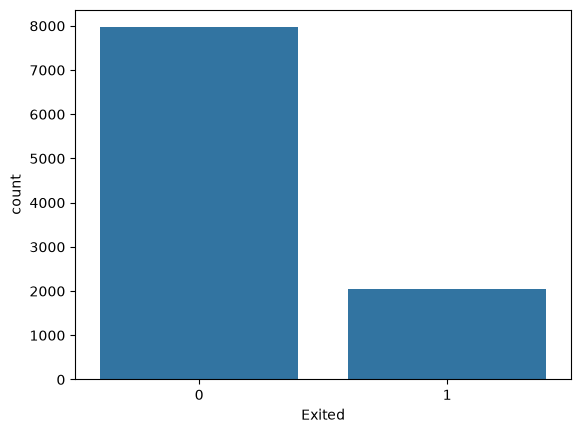

In [58]:
sns.countplot(x='Exited',data=df)
plt.show()

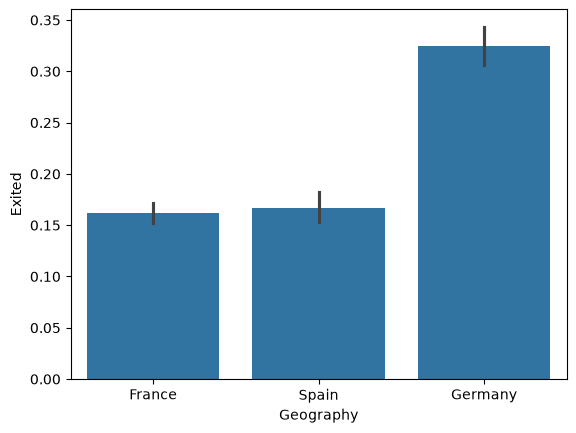

In [59]:
sns.barplot(x='Geography',y='Exited',data=df)
plt.show()

In [60]:
from scipy.stats import chi2_contingency

In [61]:
df

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,15606229,Obijiaku,771,France,Male,39,5,0.00,2,1,0,96270.64,0
9996,9997,15569892,Johnstone,516,France,Male,35,10,57369.61,1,1,1,101699.77,0
9997,9998,15584532,Liu,709,France,Female,36,7,0.00,1,0,1,42085.58,1
9998,9999,15682355,Sabbatini,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1


In [62]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.1 MB


In [63]:
df['Surname'].value_counts()

Surname
Smith        32
Scott        29
Martin       29
Walker       28
Brown        26
             ..
Salinas       1
Cleveland     1
Kashiwagi     1
Aldridge      1
Burbidge      1
Name: count, Length: 2932, dtype: int64

In [64]:
df['Geography'].value_counts()

Geography
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64

In [65]:
df['Gender'].value_counts()

Gender
Male      5457
Female    4543
Name: count, dtype: int64

In [66]:
table = pd.crosstab(df['Surname'], df['Exited'])
print(table)

chi2, p, dof, expected = chi2_contingency(table)
alpha = 0.05
print(f'Chi2: {chi2:.2f}, p-value: {p:.4f}, Degrees of freedom: {dof}')

Exited    0  1
Surname       
Abazu     2  0
Abbie     1  0
Abbott    3  1
Abdullah  0  1
Abdulov   2  0
...      .. ..
Zubarev   3  0
Zubareva  1  0
Zuev      1  0
Zuyev     1  1
Zuyeva    2  0

[2932 rows x 2 columns]
Chi2: 2786.41, p-value: 0.9720, Degrees of freedom: 2931


In [67]:
table = pd.crosstab(df['Geography'], df['Exited'])
print(table)

chi2, p, dof, expected = chi2_contingency(table)
alpha = 0.05
print(f'Chi2: {chi2:.2f}, p-value: {p:.4f}, Degrees of freedom: {dof}')

Exited        0    1
Geography           
France     4204  810
Germany    1695  814
Spain      2064  413
Chi2: 301.26, p-value: 0.0000, Degrees of freedom: 2


In [68]:
table = pd.crosstab(df['Gender'], df['Exited'])
print(table)

chi2, p, dof, expected = chi2_contingency(table)
alpha = 0.05
print(f'Chi2: {chi2:.2f}, p-value: {p:.4f}, Degrees of freedom: {dof}')

Exited     0     1
Gender            
Female  3404  1139
Male    4559   898
Chi2: 112.92, p-value: 0.0000, Degrees of freedom: 1


In [69]:
df.drop(['Surname'],axis=1,inplace=True)

In [70]:
df.columns

Index(['RowNumber', 'CustomerId', 'CreditScore', 'Geography', 'Gender', 'Age',
       'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember',
       'EstimatedSalary', 'Exited'],
      dtype='str')

In [71]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   CreditScore      10000 non-null  int64  
 3   Geography        10000 non-null  str    
 4   Gender           10000 non-null  str    
 5   Age              10000 non-null  int64  
 6   Tenure           10000 non-null  int64  
 7   Balance          10000 non-null  float64
 8   NumOfProducts    10000 non-null  int64  
 9   HasCrCard        10000 non-null  int64  
 10  IsActiveMember   10000 non-null  int64  
 11  EstimatedSalary  10000 non-null  float64
 12  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(2)
memory usage: 1015.8 KB


In [72]:
from statsmodels.formula.api import ols
from statsmodels.stats.anova import _get_covariance, anova_lm
from statsmodels.stats.anova import anova_lm

In [73]:
formula = 'Exited ~ RowNumber + CustomerId + CreditScore + Age + Tenure + Balance + NumOfProducts + HasCrCard + IsActiveMember + EstimatedSalary'
model = ols(formula,df).fit()
aov_table = anova_lm(model)
print(aov_table)

                     df       sum_sq     mean_sq           F         PR(>F)
RowNumber           1.0     0.445435    0.445435    3.142284   7.631740e-02
CustomerId          1.0     0.061919    0.061919    0.436800   5.086865e-01
CreditScore         1.0     1.179416    1.179416    8.320086   3.929289e-03
Age                 1.0   132.031001  132.031001  931.400882  1.165075e-195
Tenure              1.0     0.209576    0.209576    1.478433   2.240487e-01
Balance             1.0    19.729772   19.729772  139.181912   6.542283e-32
NumOfProducts       1.0     0.042919    0.042919    0.302771   5.821628e-01
HasCrCard           1.0     0.007963    0.007963    0.056173   8.126550e-01
IsActiveMember      1.0    52.166994   52.166994  368.007393   1.414937e-80
EstimatedSalary     1.0     0.194529    0.194529    1.372287   2.414472e-01
Residual         9989.0  1415.993576    0.141755         NaN            NaN


In [74]:
df.drop(['RowNumber','CustomerId','CreditScore','Age','Tenure','Balance','NumOfProducts','HasCrCard','IsActiveMember','EstimatedSalary'],axis=1,inplace=True)

In [75]:
df.columns

Index(['Geography', 'Gender', 'Exited'], dtype='str')

In [76]:
x = df.drop('Exited', axis=1)
y = df['Exited']

In [77]:
df['Exited'].value_counts()

Exited
0    7963
1    2037
Name: count, dtype: int64

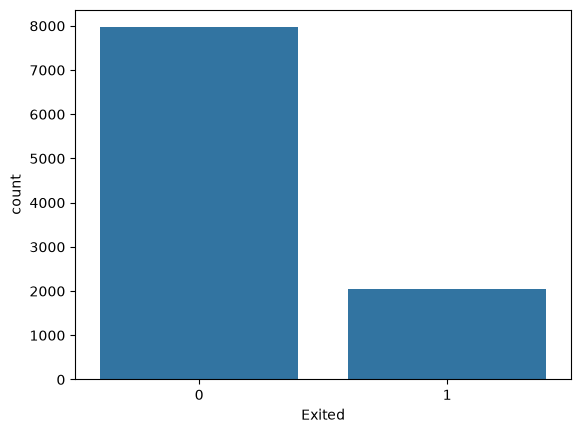

In [78]:
sns.countplot(x='Exited',data=df)
plt.show()

In [79]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   Geography  10000 non-null  str  
 1   Gender     10000 non-null  str  
 2   Exited     10000 non-null  int64
dtypes: int64(1), str(2)
memory usage: 234.5 KB


In [80]:
from sklearn.preprocessing import OrdinalEncoder
o=OrdinalEncoder()
df[['Geography']]=o.fit_transform(df[['Geography']])
df[['Gender']]=o.fit_transform(df[['Gender']])

In [81]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Geography  10000 non-null  float64
 1   Gender     10000 non-null  float64
 2   Exited     10000 non-null  int64  
dtypes: float64(2), int64(1)
memory usage: 234.5 KB


In [82]:
from imblearn.over_sampling import SMOTE

In [83]:
x=df.drop(columns="Exited")
y=df["Exited"]
#smote=SMOTE(sampling_strategy="minority")
smote= SMOTE(sampling_strategy="minority")                                 #pip install imbalanced-learn scikit-learn -y
x_sm,y_sm=smote.fit_resample(x,y)                                          ##reinstall with compatible version

                                                                           #pip install scikit-learn==1.3.2 imbalanced-learn==0.1                                                                       # reinstall kernal
                                                                           #from imblearn.over_sampling import SMOT                                                                          #print(imblearn._version_)
print(x_sm.shape)
print(y_sm.shape)

(15926, 2)
(15926,)


In [84]:
y_sm.value_counts()

Exited
1    7963
0    7963
Name: count, dtype: int64

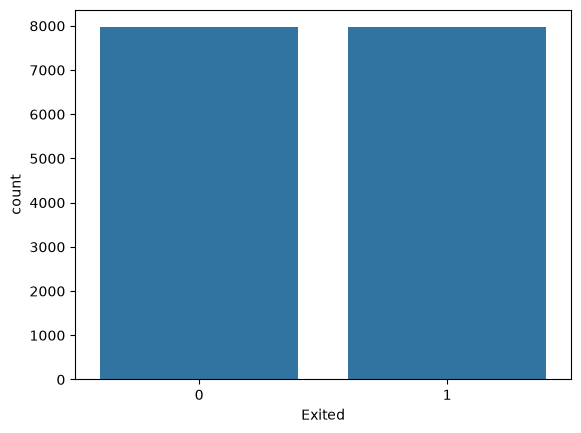

In [85]:
sns.countplot(x=y_sm)
plt.show()

In [86]:
from sklearn.preprocessing import MinMaxScaler  #StandardScaler
sc=MinMaxScaler()
c=sc.fit_transform(x_sm)
print(c)

[[0. 0.]
 [1. 0.]
 [0. 0.]
 ...
 [1. 0.]
 [0. 1.]
 [0. 1.]]


In [87]:
from sklearn.model_selection import train_test_split
x_smtrain,x_smtest,y_smtrain,y_smtest=train_test_split(x_sm,y_sm,test_size=0.20,random_state=4)
print(x_smtrain.shape)
print(x_smtest.shape)
print(y_smtrain.shape)
print(y_smtest.shape)
from sklearn.linear_model import LogisticRegression  #LinearRegression
lr=LogisticRegression()
lr.fit(x_smtrain,y_smtrain)
y_pred=lr.predict(x_smtrain)
y_pred

(12740, 2)
(3186, 2)
(12740,)
(3186,)


array([1, 0, 1, ..., 0, 0, 1], shape=(12740,))

In [88]:
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report  #r2_score,mean_squared_error,mean_absolute_error
print(accuracy_score(y_smtrain,y_pred))
print(confusion_matrix(y_smtrain,y_pred))
print(classification_report(y_smtrain,y_pred))

0.5629513343799059
[[3588 2758]
 [2810 3584]]
              precision    recall  f1-score   support

           0       0.56      0.57      0.56      6346
           1       0.57      0.56      0.56      6394

    accuracy                           0.56     12740
   macro avg       0.56      0.56      0.56     12740
weighted avg       0.56      0.56      0.56     12740



In [89]:
from sklearn.linear_model import LogisticRegression  #LinearRegression
lr=LogisticRegression()
lr.fit(x_smtrain,y_smtrain)
y_pred=lr.predict(x_smtest)
y_pred

array([1, 1, 1, ..., 0, 0, 1], shape=(3186,))

In [90]:
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report  #r2_score,mean_squared_error,mean_absolute_error
print(accuracy_score(y_smtest,y_pred))
print(confusion_matrix(y_smtest,y_pred))
print(classification_report(y_smtest,y_pred))

0.5816070307595731
[[971 646]
 [687 882]]
              precision    recall  f1-score   support

           0       0.59      0.60      0.59      1617
           1       0.58      0.56      0.57      1569

    accuracy                           0.58      3186
   macro avg       0.58      0.58      0.58      3186
weighted avg       0.58      0.58      0.58      3186

